In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

In [2]:
os.makedirs('images', exist_ok=True)

print("Please Upload The Required Images:")
print("- soduku2.jpg")
print("- highway-lanes.jpg")

uploaded = files.upload()

for filename in uploaded.keys():
  os.rename(filename, f"images/{filename}")
  print(f"{filename} Uploaded Successfully.")

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Please Upload The Required Images:
- soduku2.jpg
- highway-lanes.jpg


Saving highway-lanes.jpg to highway-lanes.jpg
Saving sudoku.jpg to sudoku.jpg
highway-lanes.jpg Uploaded Successfully.
sudoku.jpg Uploaded Successfully.

Contents Of Images Folder:
['highway-lanes.jpg', 'sudoku.jpg']


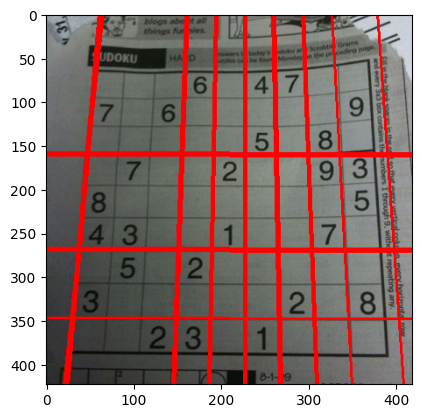

In [10]:
img = cv2.imread('images/sudoku.jpg')

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

edges = cv2.Canny(gray, 50, 150)

lines = cv2.HoughLines(edges, 1, np.pi / 180, 200)

for line in lines:
    rho, theta = line[0]
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a*rho
    y0 = b*rho
    x1 = int(x0 + 1000* (-b))
    y1 = int(y0 + 1000* (a))
    x2 = int(x0 - 1000* (-b))
    y2 = int(y0 - 1000* (a))
    cv2.line(img, (x1,y1), (x2,y2), (0,0,255), 2)

plt.imshow(img[...,::-1])

plt.show()

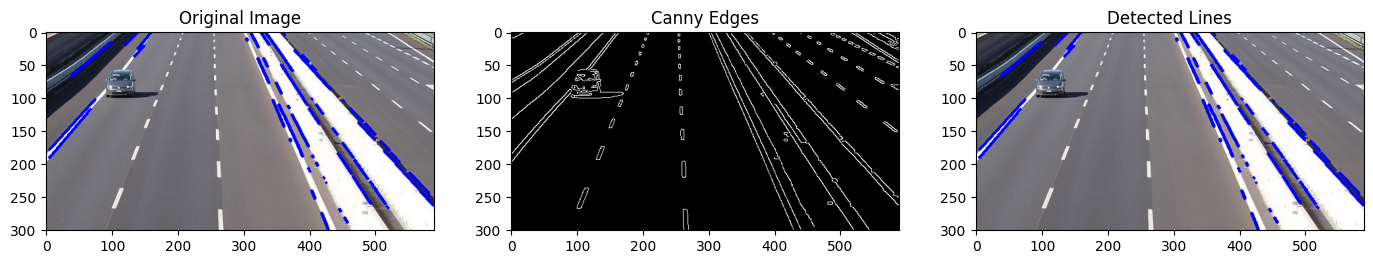

In [15]:
img2 = cv2.imread('images/highway-lanes.jpg')
img2 = img2.copy()

blured = cv2.GaussianBlur(img2, (5,5), 0)

gray = cv2.cvtColor(blured, cv2.COLOR_BGR2GRAY)

edges = cv2.Canny(gray, 50, 200)

lines = cv2.HoughLinesP(edges, 1, np.pi / 180, 100)

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line
        cv2.line(img2, (x1, y1), (x2, y2), (255, 0, 0), 3)

plt.figure(figsize=(17, 8))

plt.subplot(1, 3, 1)
plt.imshow(img2[...,::-1])
plt.title('Original Image')

plt.subplot(1, 3, 2)
plt.imshow(edges, cmap='gray')
plt.title('Canny Edges')

plt.subplot(1, 3, 3)
plt.imshow(img2[...,::-1])
plt.title('Detected Lines')

plt.show()